# 2.1. Нелинейные уравнения

Методы простой итерации и Ньютона. Данные — из `data/lab2/2_1/`.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
DATA = ROOT / "data" / "lab2" / "2_1"

from lab1.dataio import read_scalar
from lab2.dataio import read_coeffs
from lab2.nonlinear1d import (
    make_polynomial,
    make_phi_relaxation,
    simple_iteration,
    newton,
)
import matplotlib.pyplot as plt

coeffs = read_coeffs(DATA / "coeffs.txt")
eps = read_scalar(DATA / "eps.txt")
x0 = read_scalar(DATA / "x0.txt")
lam = read_scalar(DATA / "lambda.txt")
f, df = make_polynomial(coeffs)
phi = make_phi_relaxation(f, lam)

print("coeffs (asc) =", coeffs)
print("ε =", eps)
print("x0 =", x0)
print("λ =", lam)

coeffs (asc) = [3.0, -2.0, -3.0, 1.0]
ε = 1e-06
x0 = 0.9
λ = -0.2


## Графическая локализация корня

Сканируем знаки $f(x)$ и строим график. Ищем **положительный** корень.

x		f(x)
  -2.0	  -13.000000
  -1.9	  -10.889000
  -1.8	   -8.952000
  -1.7	   -7.183000
  -1.6	   -5.576000
  -1.5	   -4.125000
  -1.4	   -2.824000
  -1.3	   -1.667000
  -1.2	   -0.648000
  -1.1	    0.239000
  -1.0	    1.000000
  -0.9	    1.641000
  -0.8	    2.168000
  -0.7	    2.587000
  -0.6	    2.904000
  -0.5	    3.125000
  -0.4	    3.256000
  -0.3	    3.303000
  -0.2	    3.272000
  -0.1	    3.169000
   0.0	    3.000000
   0.1	    2.771000
   0.2	    2.488000
   0.3	    2.157000
   0.4	    1.784000
   0.5	    1.375000
   0.6	    0.936000
   0.7	    0.473000
   0.8	   -0.008000
   0.9	   -0.501000
   1.0	   -1.000000
   1.1	   -1.499000
   1.2	   -1.992000
   1.3	   -2.473000
   1.4	   -2.936000
   1.5	   -3.375000
   1.6	   -3.784000
   1.7	   -4.157000
   1.8	   -4.488000
   1.9	   -4.771000
   2.0	   -5.000000
   2.1	   -5.169000
   2.2	   -5.272000
   2.3	   -5.303000
   2.4	   -5.256000
   2.5	   -5.125000
   2.6	   -4.904000
   2.7	   -4.587000
   2.8	   -4.168000
   2.9	   -3

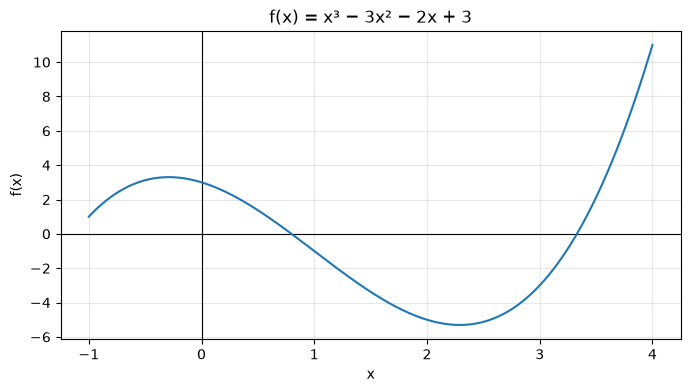

начальное приближение из файла x0 = 0.9 (около первого положительного корня)


In [2]:
print("x\t\tf(x)")
prev_x, prev_f = None, None
intervals = []
xs_scan = [i * 0.1 for i in range(-20, 51)]
for x in xs_scan:
    fx = f(x)
    print(f"{x:6.1f}\t{fx:12.6f}")
    if prev_f is not None and prev_f * fx < 0:
        intervals.append((prev_x, x))
    prev_x, prev_f = x, fx

print("\nинтервалы смены знака:", intervals)
pos = [(a, b) for a, b in intervals if a >= 0]
print("положительные интервалы:", pos)

xs = [i * 0.02 for i in range(-50, 201)]
ys = [f(x) for x in xs]
plt.figure(figsize=(8, 4))
plt.axhline(0, color="k", lw=0.8)
plt.axvline(0, color="k", lw=0.8)
plt.plot(xs, ys)
plt.xlabel("x")
plt.ylabel("f(x)")
plt.title("f(x) = x³ − 3x² − 2x + 3")
plt.grid(True, alpha=0.3)
plt.show()

print(f"начальное приближение из файла x0 = {x0} (около первого положительного корня)")

## Метод простой итерации

$\varphi(x) = x - \lambda f(x)$, параметр $\lambda$ из файла (условие $|\varphi'| < 1$ вблизи корня).

In [3]:
x_si, n_si, hist_si = simple_iteration(phi, x0, eps)
print("корень (простая итерация) =", x_si)
print("итераций =", n_si)
print("|f(x)| =", abs(f(x_si)))
print("погрешность по итерациям:")
for i, e in enumerate(hist_si, 1):
    print(f"  {i:3d}  {e:.6e}")

корень (простая итерация) = 0.7983603450253938
итераций = 4
|f(x)| = 1.012131438660191e-07
погрешность по итерациям:
    1  1.002000e-01
    2  1.404805e-03
    3  3.402039e-05
    4  8.297850e-07


## Метод Ньютона

In [4]:
x_nt, n_nt, hist_nt = newton(f, df, x0, eps)
print("корень (Ньютон) =", x_nt)
print("итераций =", n_nt)
print("|f(x)| =", abs(f(x_nt)))
print("погрешность по итерациям:")
for i, e in enumerate(hist_nt, 1):
    print(f"  {i:3d}  {e:.6e}")

корень (Ньютон) = 0.7983603242765962
итераций = 3
|f(x)| = 4.218847493575595e-15
погрешность по итерациям:
    1  1.008048e-01
    2  8.347606e-04
    3  8.617408e-08


## Сравнение сходимости

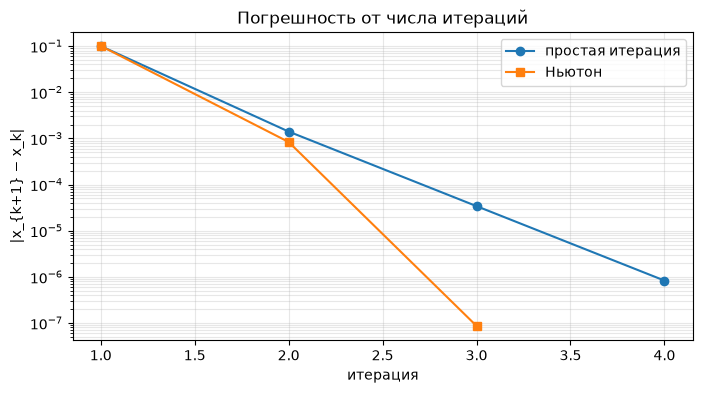

простая итерация: x = 0.7983603450, n = 4
Ньютон:           x = 0.7983603243, n = 3


In [5]:
plt.figure(figsize=(8, 4))
plt.semilogy(range(1, len(hist_si) + 1), hist_si, "o-", label="простая итерация")
plt.semilogy(range(1, len(hist_nt) + 1), hist_nt, "s-", label="Ньютон")
plt.xlabel("итерация")
plt.ylabel("|x_{k+1} − x_k|")
plt.title("Погрешность от числа итераций")
plt.grid(True, which="both", alpha=0.3)
plt.legend()
plt.show()

print(f"простая итерация: x = {x_si:.10f}, n = {n_si}")
print(f"Ньютон:           x = {x_nt:.10f}, n = {n_nt}")